**E_MEANS PARA CUANTIFICAR TINY LLM**

In [1]:
!git clone --depth 1 https://github.com/facebookresearch/faiss.git faiss_repo

Cloning into 'faiss_repo'...
remote: Enumerating objects: 1300, done.
remote: Counting objects: 100% (1300/1300), done.
remote: Compressing objects: 100% (1154/1154), done.
remote: Total 1300 (delta 200), reused 483 (delta 137), pack-reused 0 (from 0)
Receiving objects: 100% (1300/1300), 3.39 MiB | 3.52 MiB/s, done.
Resolving deltas: 100% (200/200), done.
Updating files: 100% (1224/1224), done.


In [4]:
%pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 35.5 MB/s  0:00:00m0:00:010:01
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, sys, copy, time, math
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel
from vvtk_quant.quant import nearest_index
from common_seq import DEVICE, OUT, tiny_shakespeare, CharLM, lm_batch, lm_eval, lm_sample, cosine
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.backends.cuda.matmul.allow_tf32 = True

In [3]:
train_ids, val_ids, itos = tiny_shakespeare()
print(f"train {len(train_ids):,} chars, val {len(val_ids):,} chars, vocabulary {len(itos)}")
CTX, BATCH = 256, 64
torch.manual_seed(0)
model = CharLM(len(itos), d=256, layers=4, heads=4).to(DEVICE)
n_lin = sum(m.weight.numel() for m in model.modules() if isinstance(m, nn.Linear))
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M, of which in nn.Linear: {n_lin / 1e6:.2f} M")

train 1,003,854 chars, val 111,540 chars, vocabulary 65
parameters: 3.19 M, of which in nn.Linear: 3.16 M


In [4]:
def train_lm(model, steps, lr, step_hook=None, seed=0, log_every=500, wd=0.1):
    opt = torch.optim.AdamW(model.parameters(), lr, betas=(0.9, 0.95), weight_decay=wd)
    sched = cosine(opt, steps, warmup=min(200, steps // 10))
    g = torch.Generator().manual_seed(seed)
    curve = []
    t0 = time.time()
    for s in range(steps):
        model.train()
        if step_hook is not None:
            step_hook(s, steps)
        x, y = lm_batch(train_ids, BATCH, CTX, g)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE.type == "cuda"):
            loss = F.cross_entropy(model(x).flatten(0, 1).float(), y.flatten())
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if (s + 1) % log_every == 0 or s + 1 == steps:
            v = lm_eval(model, val_ids, CTX)
            curve.append((s + 1, v))
            print(f"    step {s + 1:>5}/{steps}  train {loss.item():.3f}  val {v:.3f}  ({time.time() - t0:.0f}s)")
    return curve

ckpt = os.path.join(OUT, "charlm_fp32.pth")
if os.path.exists(ckpt):
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print("loaded", ckpt)
else:
    train_lm(model, 3000, 1e-3)
    torch.save(model.state_dict(), ckpt)
val_fp32 = lm_eval(model, val_ids, CTX)
print(f"fp32 validation loss: {val_fp32:.3f} nats/char")

loaded /extra/scratch05/alumno1/vvtk_quant/examples/out/charlm_fp32.pth
fp32 validation loss: 1.494 nats/char


In [5]:
def wrap(m, b, method, **kw):
    q = VVTK_QModel(copy.deepcopy(m), b=b, module_types=[nn.Linear], **kw)
    q.calibrate_quant(method=method)
    return q

In [29]:
QSTEPS, QLR, T0, T1 = 600, 3e-4, 2.0, 40.0
CONTENDERS = {
"soft-lloyd":        dict(mode="soft", method="lloyd"),
}

def qat(name, b):
    cfg = CONTENDERS[name]
    torch.manual_seed(0)
    if cfg is None:
        q = copy.deepcopy(model)
    else:
        cfg = dict(cfg); meth = cfg.pop("method")
        q = wrap(model, b, meth, temp=T0, **cfg)
    def hook(s, n):
        if cfg is not None and cfg["mode"] == "soft":
            q.update_temp(T0 * (T1 / T0) ** (s / (n - 1)))
    start = lm_eval(q, val_ids, CTX)
    curve = [(0, start)] + train_lm(q, QSTEPS, QLR, step_hook=hook, log_every=100, wd=0.0)
    return q, curve

R = {}

# Experimentos VVTK con QAT
print("--- soft-lloyd, 2 bits")
R[("soft-lloyd", 2)] = qat("soft-lloyd", 2)

--- soft-lloyd, 2 bits
    step   100/600  train 1.214  val 1.646  (34s)
    step   200/600  train 1.177  val 1.613  (69s)
    step   300/600  train 1.166  val 1.559  (103s)
    step   400/600  train 1.199  val 1.529  (138s)
    step   500/600  train 1.169  val 1.516  (172s)
    step   600/600  train 1.169  val 1.513  (206s)


In [30]:
import copy
import numpy as np
import torch
import torch.nn as nn
from faiss.contrib.e_means import Emeans

def vq_emeans(model, d=2, K=16, nepochs=5):
    # cuantización vectorial del modelo model con 2 bits/peso (4 bits/vector), un codebook de 16 palabras código (centroides) y 5 épocas de entrenamiento
    model_q = copy.deepcopy(model)
    codebooks = {}
    for name, layer in model_q.named_modules():
        if not isinstance(layer, nn.Linear):
            continue
        # Extraer pesos originales
        W = layer.weight.detach().cpu().numpy()
        shape = W.shape

        # Agrupar en vectores
        x = np.ascontiguousarray(
            W.reshape(-1, d),
            dtype=np.float32
        )

        # Convertir a tensor PyTorch en CPU
        xg = torch.from_numpy(x)

        assert torch.isfinite(xg).all()

        # E-means original de FAISS
        em = Emeans(d, K, nepochs=nepochs)

        centroids, labels = em.train(xg)

        # Reconstruir pesos
        W_q = centroids[labels].reshape(shape)

        # Sustituir pesos de la capa
        with torch.no_grad():
            layer.weight.copy_(
                W_q.to(
                    device=layer.weight.device,
                    dtype=layer.weight.dtype
                )
            )

        codebooks[name] = {
            "centroids": centroids,
            "labels": labels
        }
    return model_q, codebooks

In [31]:
model_emeans, results_emeans = vq_emeans(model,d=2,K=16,nepochs=5)

**E_means con qat**

1. calculamos centroides y asignaciones iniciales de los vectores a dichas centroides
2. Mantendremos las asignaciones fijas durante todo el entrenamiento
3. Entrenaremos los centroides con qat
4. en cada paso forward se reconstruyen los pesos a partir de los centroides actuales y las asignaciones
5. se usa actualización por gradiente

In [9]:
# creación de una capa Linear cuantizada con E-means
class EmeansQATLinear(nn.Module):
    def __init__(self, centroids, labels, weight_shape, bias=None):
        super().__init__()

        # Centroides entrenables
        self.centroids = nn.Parameter(
            torch.as_tensor(centroids, dtype=torch.float32).clone()
        )

        # Asignaciones fijas: no son parámetros entrenables
        self.register_buffer(
            "labels",
            torch.as_tensor(labels, dtype=torch.long).reshape(-1).clone()
        )

        self.weight_shape = weight_shape

        if bias is not None:
            self.bias = nn.Parameter(bias.detach().clone())
        else:
            self.register_parameter("bias", None)

    def forward(self, x):

        # Reconstrucción de los pesos usando los centroides actuales
        Wq = self.centroids[self.labels].reshape(self.weight_shape)

        return F.linear(x, Wq, self.bias)

In [10]:
# Sustituimos capas lineales por las del nuevo modelo recalculado
def replace_with_emeans_qat(module, d=2, K=16, nepochs=5):

    for name, layer in list(module.named_children()):

        if isinstance(layer, nn.Linear): # si la capa en la que nos encontramos es lineal, cuantifica las matrices de pesos de esa capa

            # Extraer pesos originales
            W = layer.weight.detach().cpu().numpy() # pesos originales de la capa en formato numpy
            shape = W.shape # guardamos dimensiones originales de la matriz de pesos

            assert W.size % d == 0 # comprobamos que el nº de elementos de la matriz sea divisible entre d (queremos dividir todos los pesos en vectores de dimension d)

            # Agrupar pesos en vectores: transformamos matriz de pesos en vectores que usará e-means
            x = np.ascontiguousarray(
                W.reshape(-1, d),
                dtype=np.float32
            )
            # Matriz cuantizada: W_q=reshape(C[labels]), donde C son las centroides y labels el vector que contiene en el índice del dato la centroide asignada a ese dato

            xg = torch.from_numpy(x) # convierte a tensor de pytorch

            # Ejecutar E-means
            em = Emeans(d, K, nepochs=nepochs) # ejecución del algoritmo sobre vectores de pesos
            centroids, labels = em.train(xg) # entrenamos con los vectores de pesos de la capa

            # Crear nueva capa cuantizada (con los valores calculados). Aquí se hace también la operación forward, que permite a su vez actualizar los centroides mediante backpropagation
            q_layer = EmeansQATLinear(
                centroids=centroids, # vectores que forman el codebook
                labels=labels, # qué centroide representa cada vector original
                weight_shape=shape,
                bias=layer.bias # y=x*Wtraspuesta+bias
            )

            q_layer = q_layer.to(
                device=layer.weight.device,
                dtype=layer.weight.dtype
            )

            setattr(module, name, q_layer) # sustitución capa original

        else: # cuando no es una capa linear
            replace_with_emeans_qat(
                layer, d=d, K=K, nepochs=nepochs
            )

    return module

In [12]:
# Crear el modelo emeans mediante qat
torch.manual_seed(0)
model_emeans_qat = copy.deepcopy(model)
model_emeans_qat = replace_with_emeans_qat(model_emeans_qat,d=2,K=16,nepochs=5)

In [13]:
# entrenar el modelo qat
QSTEPS, QLR = 600, 3e-4

# Entrenamiento QAT
curve_emeans_qat = train_lm(model_emeans_qat,QSTEPS,QLR,log_every=100,wd=0.0)
val_emeans_qat = lm_eval(model_emeans_qat, val_ids, CTX)

print(f"E-means QAT: {val_emeans_qat:.4f}")

    step   100/600  train 1.334  val 1.539  (35s)
    step   200/600  train 1.301  val 1.532  (71s)
    step   300/600  train 1.303  val 1.527  (106s)
    step   400/600  train 1.318  val 1.526  (141s)
    step   500/600  train 1.276  val 1.526  (176s)
    step   600/600  train 1.269  val 1.526  (212s)
E-means QAT: 1.5261


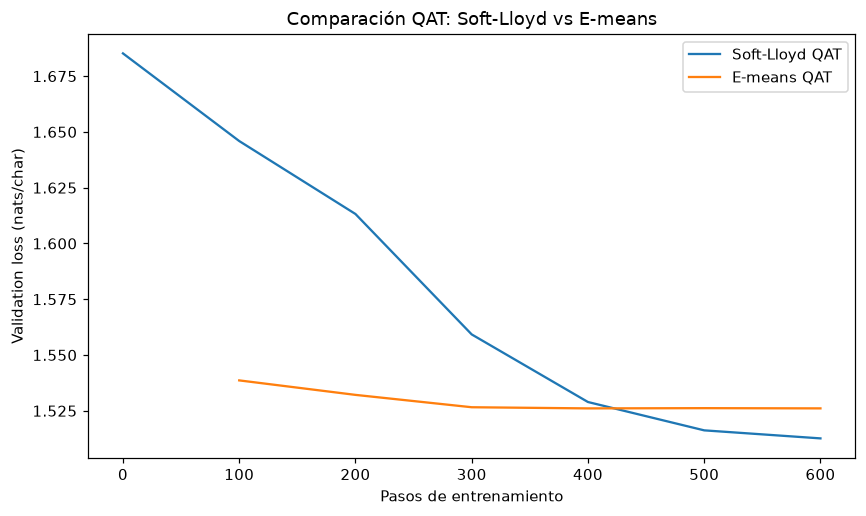

In [32]:
import matplotlib.pyplot as plt
steps_emeans = [s for s, v in curve_emeans_qat]
loss_emeans = [v for s, v in curve_emeans_qat]
curve_soft = R[("soft-lloyd", 2)][1]
steps_soft = [s for s, v in curve_soft]
loss_soft = [v for s, v in curve_soft]

plt.figure(figsize=(9, 5))
plt.plot(steps_soft, loss_soft, label="Soft-Lloyd QAT")
plt.plot(steps_emeans, loss_emeans, label="E-means QAT")
plt.xlabel("Pasos de entrenamiento")
plt.ylabel("Validation loss (nats/char)")
plt.title("Comparación QAT: Soft-Lloyd vs E-means")
plt.legend()
plt.grid()
plt.show()

Cuando usamos menos pasos de entrenamiento, e-means demuestra mucha mejor convergencia al usar QAT que Soft-Lloyd. Probaremos a poner 200 pasos de entrenamiento en lugar de 600 y ver los resultados

**Loss**

In [15]:
model.load_state_dict(torch.load(os.path.join(OUT, "charlm_fp32.pth"),map_location=DEVICE))
val_emeans = lm_eval(model_emeans, val_ids, CTX)
print(f"E-means 2 bits ptq: {val_emeans:.4f}")

E-means 2 bits ptq: 1.6345


In [16]:
model_soft=wrap(model, 2, "lloyd", mode="soft")
val_lloyd = lm_eval(model_soft, val_ids, CTX)

# Soft-Lloyd QAT
model_soft_qat, curve_soft = R[("soft-lloyd", 2)]
val_soft_qat = lm_eval(model_soft_qat, val_ids, CTX)

print("\nComparación a 2 bits por peso: val_loss")
print(f"FP32:              {lm_eval(model, val_ids, CTX):.4f}")
print(f"Soft-Lloyd qat:    {val_soft_qat:.4f}")
print(f"Soft-Lloyd ptq:    {val_lloyd:.4f}")
print(f"E-means ptq:       {val_emeans:.4f}")
print(f"E-means qat:       {val_emeans_qat:.4f}")


Comparación a 2 bits por peso: val_loss
FP32:              1.4937
Soft-Lloyd qat:    1.5126
Soft-Lloyd ptq:    1.6852
E-means ptq:       1.6345
E-means qat:       1.5261


**Perplexity (incertidumbre)**

In [17]:
ppl_fp32 = np.exp(val_fp32)
ppl_lloyd=np.exp(val_lloyd)
ppl_lloyd_qat=np.exp(val_soft_qat)
ppl_emeans = np.exp(val_emeans)
ppl_emeans_qat = np.exp(val_emeans_qat)

print(f"PPL FP32: {ppl_fp32:.4f}")
print(f"PPL soft-Lloyd ptq: {ppl_lloyd:.4f}")
print(f"PPL soft-Lloyd qat: {ppl_lloyd_qat:.4f}")
print(f"PPL E-means ptq: {ppl_emeans:.4f}")
print(f"PPL E-means qat: {ppl_emeans_qat:.4f}")

PPL FP32: 4.4533
PPL soft-Lloyd ptq: 5.3935
PPL soft-Lloyd qat: 4.5386
PPL E-means ptq: 5.1270
PPL E-means qat: 4.6001


**Memoria utilizada por cada modelo y su reducción con respecto a FP32**

In [18]:
def memory_emeans(codebooks, model, K=16):

    total_bits = 0

    # Codebooks e índices
    for name, data in codebooks.items():

        centroids = data["centroids"]
        labels = data["labels"]

        total_bits += (
            centroids.numel() * centroids.element_size() * 8
        )

        total_bits += labels.numel() * np.log2(K)

    # Bias de las capas lineales
    for layer in model.modules():
        if isinstance(layer, EmeansQATLinear):
            if layer.bias is not None:
                total_bits += (
                    layer.bias.numel() *
                    layer.bias.element_size() * 8
                )

    return total_bits / 8 / (1024**2)

In [19]:
def memory_emeans_qat(model, K=16):

    total_bits = 0

    for layer in model.modules():

        if isinstance(layer, EmeansQATLinear):

            total_bits += (
                layer.centroids.numel() *
                layer.centroids.element_size() * 8
            )

            total_bits += layer.labels.numel() * np.log2(K)

            if layer.bias is not None:
                total_bits += (
                    layer.bias.numel() *
                    layer.bias.element_size() * 8
                )

    return total_bits / 8 / (1024**2)


mem_emeans_qat = memory_emeans_qat(model_emeans_qat)

In [33]:
mem_fp32=sum(
    t.numel() * t.element_size()
    for t in model.state_dict().values()
)/(1024**2)

q_qat = copy.deepcopy(model_soft_qat)
q_qat.apply_quant()
q_qat.save("soft_lloyd_qat.q.gz")
q_ptq=copy.deepcopy(model_soft)
q_ptq.apply_quant()
q_ptq.save("soft_lloyd_ptq.q.gz")
mem_soft_qat = os.path.getsize("soft_lloyd_qat.q.gz")/(1024**2)
mem_soft_ptq = os.path.getsize("soft_lloyd_ptq.q.gz")/(1024**2)
mem_emeans_ptq=memory_emeans(results_emeans,model_emeans,K=16)
mem_emeans_qat=memory_emeans_qat(model_emeans_qat,K=16)

print(f"Memoria FP32: {mem_fp32:.4f} MB")
print(f"Memoria soft-lloyd ptq: {mem_soft_ptq:.4f} MB, reducción={(1-mem_soft_ptq/mem_fp32)*100} %")
print(f"Memoria soft-lloyd qat: {mem_soft_qat:.4f} MB, reducción={(1-mem_soft_qat/mem_fp32)*100} %")
print(f"Memoria e-means ptq: {mem_emeans_ptq:.4f} MB, reducción={(1-mem_emeans_ptq/mem_fp32)*100} %")
print(f"Memoria e-means qat: {mem_emeans_qat:.4f} MB, reducción={(1-mem_emeans_qat/mem_fp32)*100} %")

Memoria FP32: 12.1641 MB
Memoria soft-lloyd ptq: 0.8168 MB, reducción=93.28522336123154 %
Memoria soft-lloyd qat: 0.8198 MB, reducción=93.2608406591201 %
Memoria e-means ptq: 0.7570 MB, reducción=93.77659360950545 %
Memoria e-means qat: 0.7766 MB, reducción=93.61602842003853 %


e-means consigue una reducción de memoria mayor que soft-lloyd, pero no por mucho.

**QAT Soft-Lloyd vs E-means con 200 pasos de entrenamiento**

In [36]:
print("COMPARACIÓN VALIDATION LOSS")
print(f"{'Método':<20} {'100 pasos':>12} {'200 pasos':>12} "
      f"{'300 pasos':>12} {'400 pasos':>10} {'500 pasos':>10} {'600 pasos':>10}")

# Extraer pérdidas de cada curva
loss_soft = [v for s, v in curve_soft if s > 0]
loss_emeans = [v for s, v in curve_emeans_qat if s > 0]

# Imprimir resultados
print(f"{'Soft-Lloyd QAT':<20}", end="")
for loss in loss_soft:
    print(f"{loss:>12.4f}", end="")

print()

print(f"{'E-means QAT':<20}", end="")
for loss in loss_emeans:
    print(f"{loss:>12.4f}", end="")

print()

COMPARACIÓN VALIDATION LOSS
Método                  100 pasos    200 pasos    300 pasos  400 pasos  500 pasos  600 pasos
Soft-Lloyd QAT            1.6459      1.6132      1.5592      1.5289      1.5162      1.5126
E-means QAT               1.5386      1.5321      1.5266      1.5261      1.5262      1.5261


Podemos hacer menos pasos usando e-means y obtener un resultado parecido al de soft-lloyd usando el triple de pasos. Esto también ayuda a que el modelo sea mucho más rápido